# F3. Prévision de l'inflation
**Nom et prénom :** MRIOUCH Asmaa  **Code Apogée :** 23008964  Groupe :3
**Filière :** S7 FIN / **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/asm1234-bit/23008964-MRIOUCH-G3

## 1. Sujet et problématique
- **Intérêt du sujet** : prévoir l'inflation à 12 mois sert aux entreprises, banques et investisseurs qui fixent prix, taux et budgets. *(à reformuler avec vos mots)*
- **Problématique** : le taux de chômage et le taux directeur américains, ajoutés aux retards de l'inflation, permettent-ils de prévoir l'inflation annuelle 12 mois plus tard mieux que la dernière valeur observée ?
- **Objectif mesurable** (fixé avant les résultats) : RMSE de test du modèle inférieur d'au moins **10 %** à celui de la référence « dernière valeur », sur les observations postérieures à décembre 2010.
- **Nature du problème** : régression supervisée sur série temporelle mensuelle (cible continue, données ordonnées dans le temps).
- **Algorithme principal** : n° 2, **Ridge**. Alternative non retenue : gradient boosting (n° 7), car les modèles à arbres n'extrapolent pas hors des valeurs vues à l'apprentissage (inflation de 2021-2022) et les retards sont très corrélés avec peu d'observations.

In [1]:
# Configuration : imports, graine, versions
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore", category=FutureWarning)
GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams["figure.dpi"] = 110
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


## 2. Jeu de données
- **Source** : FRED (Réserve fédérale de Saint-Louis). Extraction le 17/11/2026.
  - CPIAUCSL : https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL
  - UNRATE : https://fred.stlouisfed.org/graph/fredgraph.csv?id=UNRATE
  - FEDFUNDS : https://fred.stlouisfed.org/graph/fredgraph.csv?id=FEDFUNDS
- **Licence** : aucune indiquée sur les fichiers téléchargés (à vérifier sur la page de chaque série).
- **Unité d'observation** : un mois. **Fréquence** : mensuelle.
- **Cible** : inflation annuelle observée 12 mois plus tard, `infl_t+12`.
- **Adéquation** : séries longues, publiques, qui contiennent à la fois la variable à prévoir et les deux variables explicatives de la question.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| CPIAUCSL | Indice des prix à la consommation, désaisonnalisé | numérique | indice (1982-84 = 100) | brute, sert à calculer l'inflation | voir sortie ci-dessous |
| UNRATE | Taux de chômage | numérique | % | explicative | voir sortie |
| FEDFUNDS | Taux directeur effectif | numérique | % | explicative | voir sortie |
| infl | Inflation annuelle = 100 × (CPI_t / CPI_{t-12} − 1) | numérique | % | explicative | début de série |
| *_t-k | Retard de k mois (k = 1, 3, 6, 12), `shift(k)` | numérique | idem | explicative | début de série |
| infl_t+12 | Inflation annuelle 12 mois plus tard | numérique | % | **cible** | 12 dernières lignes retirées |

**Limites** : séries révisées après publication (biais d'anticipation), changements de régime (années 1980, 2008, 2020-2022), dates de début différentes.

In [2]:
# Chargement : cherche les CSV dans data/raw ; sinon dans le dépôt cloné ; sinon télécharge depuis FRED
SERIES = ["CPIAUCSL", "UNRATE", "FEDFUNDS"]
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
CANDIDATS = [Path("data/raw"), Path("../data/raw"), Path("/content/data/raw"), Path("/content")]

def charger(nom):
    for dossier in CANDIDATS:
        f = dossier / f"{nom}.csv"
        if f.exists():
            print(f"{nom} : lu dans {f}")
            return pd.read_csv(f, index_col=0, parse_dates=True, na_values=".").iloc[:, 0].astype(float).rename(nom)
    print(f"{nom} : fichier local introuvable, téléchargement depuis FRED")
    return pd.read_csv(URL + nom, index_col=0, parse_dates=True, na_values=".").iloc[:, 0].astype(float).rename(nom)

brut = pd.concat([charger(s) for s in SERIES], axis=1)
brut.index.name = "date"

print("\nDimensions :", brut.shape)
print("Période :", brut.index.min().date(), "->", brut.index.max().date())
print("Fréquence déduite :", pd.infer_freq(brut.index))
print("\nValeurs manquantes (%) :\n", (brut.isna().mean() * 100).round(2))
print("\nPremière date valide :\n", brut.apply(lambda c: c.first_valid_index().date()))
brut.head()

CPIAUCSL : fichier local introuvable, téléchargement depuis FRED
UNRATE : fichier local introuvable, téléchargement depuis FRED
FEDFUNDS : fichier local introuvable, téléchargement depuis FRED

Dimensions : (958, 3)
Période : 1947-01-01 -> 2026-10-01
Fréquence déduite : MS

Valeurs manquantes (%) :
 CPIAUCSL    0.10
UNRATE      1.36
FEDFUNDS    9.39
dtype: float64

Première date valide :
 CPIAUCSL    1947-01-01
UNRATE      1948-01-01
FEDFUNDS    1954-07-01
dtype: object


,CPIAUCSL,UNRATE,FEDFUNDS
date,,,
1947-01-01,21.48,NaN,NaN
1947-02-01,21.62,NaN,NaN
1947-03-01,22.00,NaN,NaN
1947-04-01,22.00,NaN,NaN
1947-05-01,21.95,NaN,NaN


*À rédiger (2 à 4 lignes) : ce que montrent ces sorties (taille, période, fréquence, valeurs manquantes) et ce que vous en concluez.*

## 3. Exploration

In [3]:
print(brut.describe().round(2))
print("\nDoublons de dates :", int(brut.index.duplicated().sum()))
avant = len(brut)
brut = brut.dropna()      # seuls les mois de début de série manquent : on garde les mois communs
print(f"\nLignes avant alignement : {avant}, après : {len(brut)}")
print("Période commune :", brut.index.min().date(), "->", brut.index.max().date())
print("Chômage max :", brut['UNRATE'].max(), "en", brut['UNRATE'].idxmax().date())
print("Taux directeur max :", brut['FEDFUNDS'].max(), "en", brut['FEDFUNDS'].idxmax().date())

       CPIAUCSL  UNRATE  FEDFUNDS
count    957.00  945.00    868.00
mean     126.03    5.65      4.59
std       91.25    1.70      3.52
min       21.48    2.50      0.05
25%       32.90    4.30      1.94
50%      110.40    5.40      4.24
75%      202.90    6.70      6.10
max      337.48   14.80     19.10

Doublons de dates : 0

Lignes avant alignement : 958, après : 867
Période commune : 1954-07-01 -> 2026-10-01
Chômage max : 14.8 en 2020-04-01
Taux directeur max : 19.1 en 1981-06-01


*À rédiger : décisions de qualité des données. Pas de doublons ; valeurs manquantes uniquement en début de série, donc supprimées (alignement) ; les valeurs extrêmes (chômage d'avril 2020, taux directeur du début des années 1980) sont **réelles** et ne sont pas supprimées.*

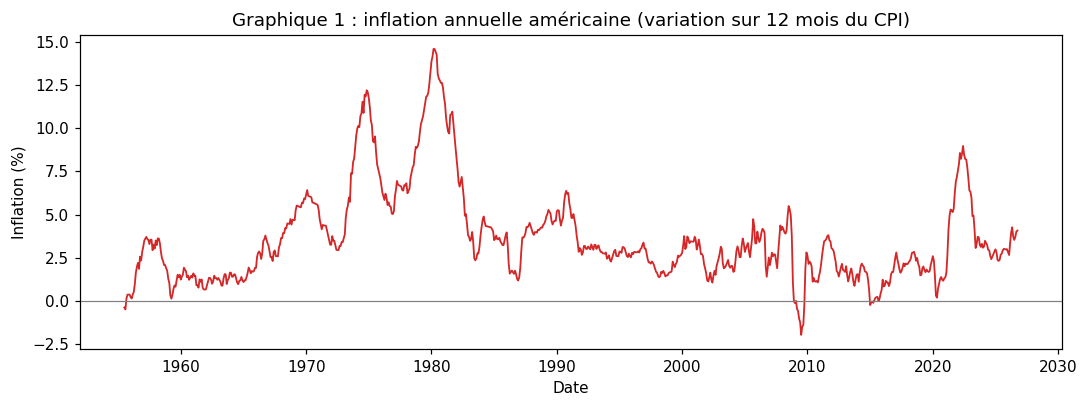

In [4]:
infl = (brut["CPIAUCSL"] / brut["CPIAUCSL"].shift(12) - 1) * 100   # variation sur 12 mois : n'utilise que le passé

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(infl.index, infl, color="tab:red", lw=1.2)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Graphique 1 : inflation annuelle américaine (variation sur 12 mois du CPI)")
ax.set_xlabel("Date"); ax.set_ylabel("Inflation (%)")
plt.tight_layout(); plt.show()

*À rédiger (2 à 4 lignes) : ce que montre le graphique 1 (pics des années 1970, creux de 2009 et 2020, remontée de 2021-2022) et ce que vous en concluez.*

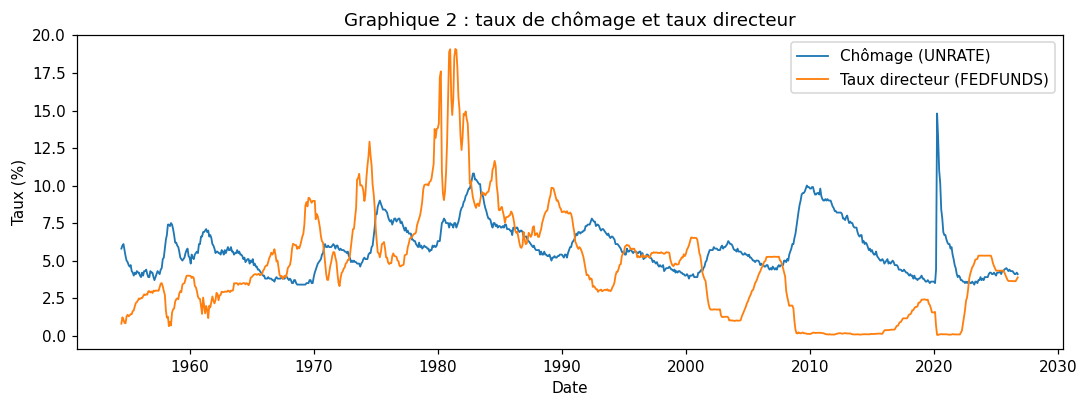

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(brut.index, brut["UNRATE"], label="Chômage (UNRATE)", lw=1.2)
ax.plot(brut.index, brut["FEDFUNDS"], label="Taux directeur (FEDFUNDS)", lw=1.2)
ax.set_title("Graphique 2 : taux de chômage et taux directeur")
ax.set_xlabel("Date"); ax.set_ylabel("Taux (%)"); ax.legend()
plt.tight_layout(); plt.show()

*À rédiger (2 à 4 lignes) : ce que montre le graphique 2 et ce que vous en concluez (les deux taux évoluent différemment selon les époques).*

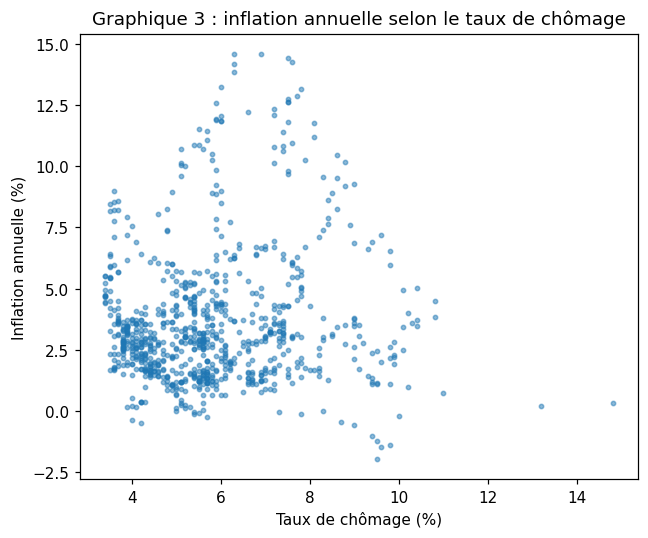

Corrélation chômage / inflation : 0.088
Corrélation taux directeur / inflation : 0.703


In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(brut["UNRATE"], infl, s=8, alpha=0.5)
ax.set_title("Graphique 3 : inflation annuelle selon le taux de chômage")
ax.set_xlabel("Taux de chômage (%)"); ax.set_ylabel("Inflation annuelle (%)")
plt.tight_layout(); plt.show()
print("Corrélation chômage / inflation :", round(infl.corr(brut["UNRATE"]), 3))
print("Corrélation taux directeur / inflation :", round(infl.corr(brut["FEDFUNDS"]), 3))

*À rédiger (2 à 4 lignes) : ce que montre le graphique 3 et les corrélations ; rappeler qu'une corrélation ne prouve pas une causalité.*

## 4. Préparation

In [7]:
HORIZON = 12
RETARDS = [0, 1, 3, 6, 12]          # 0 = valeur courante

df = pd.DataFrame({"infl": infl, "chomage": brut["UNRATE"], "taux": brut["FEDFUNDS"]}).dropna()

def nom(k):
    return "t" if k == 0 else f"t-{k}"

X = pd.DataFrame({f"{v}_{nom(k)}": df[v].shift(k) for v in df.columns for k in RETARDS})   # shift(k>0) : passé seulement
y = df["infl"].shift(-HORIZON).rename("infl_t+12")                                         # cible : 12 mois dans le futur
data = pd.concat([X, y], axis=1).dropna()

# Preuve d'alignement : la cible de la 1re ligne est bien l'inflation observée 12 mois plus tard
d0 = data.index[0]
assert np.isclose(data.loc[d0, "infl_t+12"], df.loc[d0 + pd.DateOffset(months=HORIZON), "infl"])
print("Alignement vérifié. Observations utilisables :", len(data))
data[["infl_t", "chomage_t", "taux_t", "infl_t+12"]].head(4)

Alignement vérifié. Observations utilisables : 831


,infl_t,chomage_t,taux_t,infl_t+12
date,,,,
1956-07-01,1.980568,4.4,2.75,3.297911
1956-08-01,2.208084,4.1,2.73,3.551813
1956-09-01,1.862197,3.9,2.95,3.546618
1956-10-01,2.572707,3.9,2.96,2.944384


In [8]:
# Découpage chronologique avec écart de 12 mois : toute cible du train est connue à la date de coupure
CUTOFF = pd.Timestamp("2010-12-01")
date_cible = data.index + pd.DateOffset(months=HORIZON)
m_train, m_test = date_cible <= CUTOFF, data.index > CUTOFF

cols = list(X.columns)
cols_infl = [c for c in cols if c.startswith("infl_")]
X_train, y_train = data.loc[m_train, cols], data.loc[m_train, "infl_t+12"]
X_test, y_test = data.loc[m_test, cols], data.loc[m_test, "infl_t+12"]

print(f"Train : origines {X_train.index.min().date()} -> {X_train.index.max().date()} ({len(X_train)} obs.)")
print(f"Test  : origines {X_test.index.min().date()} -> {X_test.index.max().date()} ({len(X_test)} obs.)")

Train : origines 1956-07-01 -> 2009-12-01 (642 obs.)
Test  : origines 2011-01-01 -> 2025-09-01 (177 obs.)


*À rédiger (5 à 10 lignes) : traitements (alignement, inflation annuelle, retards 0/1/3/6/12, cible à t+12), prévention des fuites (retards avec `shift(k>0)`, découpage chronologique sans mélange, écart de 12 mois, standardisation dans un Pipeline ajusté sur l'apprentissage seulement), et pourquoi la mise à l'échelle est nécessaire pour Ridge (la pénalité dépend de l'échelle des variables).*

## 5. Algorithme
**Ridge** : régression linéaire avec pénalité L2. On cherche les coefficients β qui minimisent
$$\sum_{i=1}^{n}\left(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\right)^2 + \alpha \sum_{j=1}^{p}\beta_j^2$$
où $y_i$ est la cible (inflation à 12 mois), $x_{ij}$ la variable j (standardisée) de l'observation i, $\beta_0$ l'ordonnée à l'origine, $\beta_j$ les coefficients, $n$ le nombre d'observations, $p$ le nombre de variables, et $\alpha \ge 0$ le poids de la pénalité.

*À rédiger (6 à 10 lignes) : intuition (la pénalité réduit les coefficients et stabilise le modèle quand les retards sont corrélés), paramètres appris (β) contre hyperparamètre (α, fixé par validation), effet d'un alpha petit (proche de la régression linéaire, risque de surapprentissage) et grand (coefficients écrasés vers 0, sous-apprentissage), et un second hyperparamètre ou choix important (jeu de retards).*

## 6. Protocole expérimental
- **Découpage** : entraînement = observations dont la cible est connue au 01/12/2010 ; test = origines postérieures à décembre 2010 (voir dates affichées en section 4).
- **Référence naïve** : inflation dans 12 mois = inflation d'aujourd'hui.
- **Validation** : `TimeSeriesSplit` (5 plis, écart de 12 mois), réglage de α par `GridSearchCV` sur l'apprentissage seulement : 13 valeurs de α entre 10⁻³ et 10³.
- **Métrique principale** : RMSE (points d'inflation), qui pénalise les grosses erreurs, utiles à repérer ici. **Secondaire** : MAE.
- **Test** : utilisé une seule fois, à la fin, pour la référence et deux modèles fixés d'avance (jeu complet et inflation seule).

In [9]:
tscv = TimeSeriesSplit(n_splits=5, gap=HORIZON)
for i, (a, b) in enumerate(tscv.split(X_train), 1):
    print(f"Pli {i} : train jusqu'à {X_train.index[a[-1]].date()} | validation {X_train.index[b[0]].date()} -> {X_train.index[b[-1]].date()}")

# Référence naïve sur les plis de validation
cv_ref = [rmse(y_train.iloc[v], X_train["infl_t"].iloc[v]) for _, v in tscv.split(X_train)]

def ajuster(colonnes):
    pipe = Pipeline([("sc", StandardScaler()), ("ridge", Ridge(random_state=GRAINE))])   # standardisation réajustée dans chaque pli
    gs = GridSearchCV(pipe, {"ridge__alpha": np.logspace(-3, 3, 13)}, cv=tscv,
                      scoring="neg_root_mean_squared_error", return_train_score=True)
    return gs.fit(X_train[colonnes], y_train)

gs_full, gs_infl = ajuster(cols), ajuster(cols_infl)      # 13 configurations chacun

print()
for nom_m, gs in [("Ridge complet", gs_full), ("Ridge inflation seule", gs_infl)]:
    i = gs.best_index_
    print(f"{nom_m} : alpha = {gs.best_params_['ridge__alpha']:.3g}, RMSE validation = "
          f"{-gs.cv_results_['mean_test_score'][i]:.3f} ± {gs.cv_results_['std_test_score'][i]:.3f}")
print(f"Référence : RMSE validation = {np.mean(cv_ref):.3f} ± {np.std(cv_ref):.3f}")

Pli 1 : train jusqu'à 1964-05-01 | validation 1965-06-01 -> 1974-04-01
Pli 2 : train jusqu'à 1973-04-01 | validation 1974-05-01 -> 1983-03-01
Pli 3 : train jusqu'à 1982-03-01 | validation 1983-04-01 -> 1992-02-01
Pli 4 : train jusqu'à 1991-02-01 | validation 1992-03-01 -> 2001-01-01
Pli 5 : train jusqu'à 2000-01-01 | validation 2001-02-01 -> 2009-12-01

Ridge complet : alpha = 316, RMSE validation = 2.586 ± 1.303
Ridge inflation seule : alpha = 100, RMSE validation = 2.401 ± 1.207
Référence : RMSE validation = 2.004 ± 0.788


## 7. Résultats

In [10]:
p_ref = X_test["infl_t"].values
p_full = gs_full.predict(X_test[cols])
p_infl = gs_infl.predict(X_test[cols_infl])

tab = pd.DataFrame({
    "Modèle": ["Référence (dernière valeur)", "Ridge inflation seule", "Ridge complet"],
    "RMSE validation": [np.mean(cv_ref), -gs_infl.best_score_, -gs_full.best_score_],
    "RMSE test": [rmse(y_test, p) for p in (p_ref, p_infl, p_full)],
    "MAE test": [mean_absolute_error(y_test, p) for p in (p_ref, p_infl, p_full)],
}).round(3)
display(tab)

base = tab.loc[0, "RMSE test"]
for i in (1, 2):
    gain = 100 * (1 - tab.loc[i, "RMSE test"] / base)
    print(f"{tab.loc[i, 'Modèle']} : gain vs référence = {gain:+.1f} % (objectif : au moins +10 %) -> {'atteint' if gain >= 10 else 'NON atteint'}")

# Stabilité sur deux sous-périodes (date de la cible)
cible_test = X_test.index + pd.DateOffset(months=HORIZON)
avant = cible_test <= pd.Timestamp("2019-12-31")
sp = pd.DataFrame({
    "Modèle": tab["Modèle"],
    "RMSE cible <= 2019": [rmse(y_test[avant], p[avant]) for p in (p_ref, p_infl, p_full)],
    "RMSE cible >= 2020": [rmse(y_test[~avant], p[~avant]) for p in (p_ref, p_infl, p_full)],
}).round(3)
display(sp)

,Modèle,RMSE validation,RMSE test,MAE test
0,Référence (dernière valeur),2.004,2.061,1.468
1,Ridge inflation seule,2.401,1.899,1.389
2,Ridge complet,2.586,2.181,1.615


Ridge inflation seule : gain vs référence = +7.9 % (objectif : au moins +10 %) -> NON atteint
Ridge complet : gain vs référence = -5.8 % (objectif : au moins +10 %) -> NON atteint


,Modèle,RMSE cible <= 2019,RMSE cible >= 2020
0,Référence (dernière valeur),1.076,2.813
1,Ridge inflation seule,1.208,2.480
2,Ridge complet,1.241,2.927


*À rédiger (10 à 15 lignes) : comparer chaque modèle à la référence (valeurs de RMSE et gains), dire si l'objectif de 10 % est atteint, si ajouter chômage et taux directeur aide (complet contre inflation seule), et commenter la différence avant/après 2020. Un résultat négatif honnête est valorisé.*

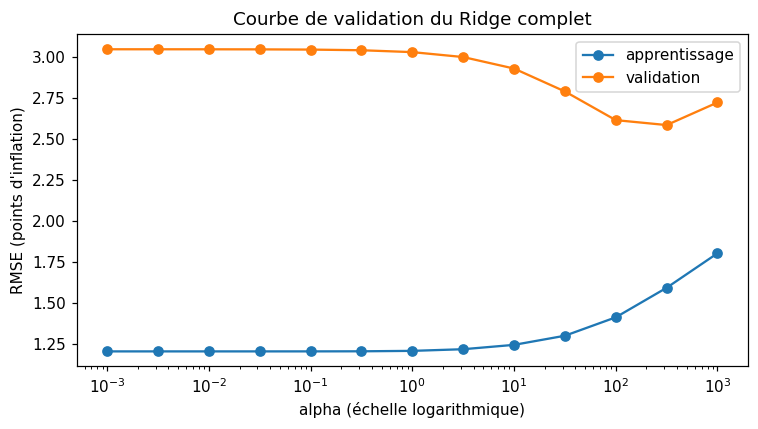

In [11]:
# Courbe de validation : erreur d'apprentissage et de validation selon alpha (surapprentissage)
r = gs_full.cv_results_
a = np.array(r["param_ridge__alpha"], dtype=float)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(a, -r["mean_train_score"], "o-", label="apprentissage")
ax.semilogx(a, -r["mean_test_score"], "o-", label="validation")
ax.set_title("Courbe de validation du Ridge complet")
ax.set_xlabel("alpha (échelle logarithmique)"); ax.set_ylabel("RMSE (points d'inflation)"); ax.legend()
plt.tight_layout(); plt.show()

*À rédiger : l'écart entre les deux courbes indique-t-il du surapprentissage ? Quel alpha est retenu et pourquoi ?*

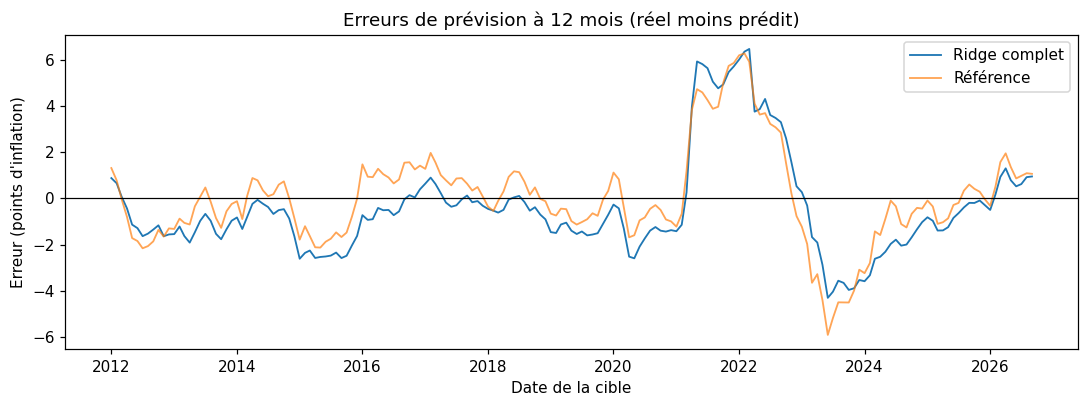

5 plus grosses erreurs (valeur absolue, points d'inflation) :
 date
2022-03-01    6.46
2022-02-01    6.34
2022-01-01    6.00
2021-05-01    5.92
2021-06-01    5.80
dtype: float64


In [12]:
# Analyse des erreurs : résidus dans le temps
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(cible_test, y_test.values - p_full, label="Ridge complet", lw=1.2)
ax.plot(cible_test, y_test.values - p_ref, label="Référence", lw=1.2, alpha=0.7)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Erreurs de prévision à 12 mois (réel moins prédit)")
ax.set_xlabel("Date de la cible"); ax.set_ylabel("Erreur (points d'inflation)"); ax.legend()
plt.tight_layout(); plt.show()

pires = pd.Series(np.abs(y_test.values - p_full), index=cible_test).nlargest(5)
print("5 plus grosses erreurs (valeur absolue, points d'inflation) :\n", pires.round(2))

*À rédiger : quand le modèle se trompe-t-il le plus (probablement 2021-2022) et pourquoi (choc d'inflation, changement de régime) ?*

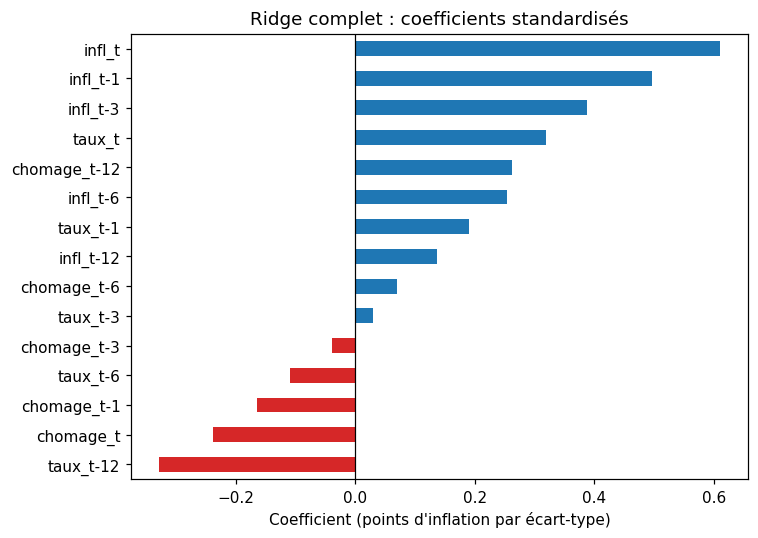

,hausse moyenne du RMSE,écart-type
Inflation,0.247,0.091
Chômage,-0.104,0.038
Taux directeur,-0.085,0.013


In [13]:
# Coefficients standardisés : à lire avec prudence (retards corrélés ; corrélation n'est pas causalité)
coef = pd.Series(gs_full.best_estimator_.named_steps["ridge"].coef_, index=cols).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
coef.plot.barh(ax=ax, color=["tab:red" if c < 0 else "tab:blue" for c in coef])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Ridge complet : coefficients standardisés")
ax.set_xlabel("Coefficient (points d'inflation par écart-type)")
plt.tight_layout(); plt.show()

# Importance par famille de variables : on mélange tous les retards d'une famille à la fois (jeu de test)
rng = np.random.default_rng(GRAINE)
base_r = rmse(y_test, p_full)
imp = {}
for fam, pref in [("Inflation", "infl_"), ("Chômage", "chomage_"), ("Taux directeur", "taux_")]:
    cs = [c for c in cols if c.startswith(pref)]
    h = []
    for _ in range(30):
        Xp = X_test[cols].copy()
        Xp[cs] = X_test[cs].values[rng.permutation(len(Xp))]
        h.append(rmse(y_test, gs_full.predict(Xp)) - base_r)
    imp[fam] = (np.mean(h), np.std(h))
display(pd.DataFrame(imp, index=["hausse moyenne du RMSE", "écart-type"]).T.round(3))

*À rédiger : quelles variables comptent le plus ? Le chômage et le taux directeur apportent-ils quelque chose ? Prudence : ce sont des corrélations, pas des causes.*

In [14]:
# Illustration d'usage sur 4 observations du test (non utilisées pour l'apprentissage)
idx = np.linspace(0, len(X_test) - 1, 4).astype(int)
ill = pd.DataFrame({
    "Date de prévision": X_test.index[idx].date,
    "Inflation actuelle (%)": X_test["infl_t"].values[idx].round(2),
    "Prédiction à 12 mois (%)": p_full[idx].round(2),
    "Valeur réelle à 12 mois (%)": y_test.values[idx].round(2),
})
ill["Erreur (points)"] = (ill["Valeur réelle à 12 mois (%)"] - ill["Prédiction à 12 mois (%)"]).round(2)
display(ill)

,Date de prévision,Inflation actuelle (%),Prédiction à 12 mois (%),Valeur réelle à 12 mois (%),Erreur (points)
0,2011-01-01,1.70,2.14,3.01,0.87
1,2015-11-01,0.44,1.65,1.68,0.03
2,2020-10-01,1.23,1.31,6.24,4.93
3,2025-09-01,3.02,3.14,4.08,0.94


*À rédiger : un commentaire par ligne (le modèle a-t-il bien ou mal anticipé, et pourquoi ?).*

## 8. Analyse critique
*À rédiger (5 à 8 lignes), par exemple :*
- *Biais d'anticipation : les données téléchargées sont les versions actuelles, révisées (désaisonnalisation de CPIAUCSL et UNRATE), pas celles connues à l'époque ; la base ALFRED conserve les versions successives. Les performances sont probablement trop optimistes.*
- *Délai de publication : le CPI du mois t n'est connu qu'avec retard, donc l'usage de la valeur courante est optimiste.*
- *Un seul découpage (coupure fin 2010) : tester d'autres dates de coupure.*
- *Changements de régime (1980, 2008, 2020-2022) : un modèle linéaire unique s'adapte mal.*
- *Pistes : données vintage ALFRED, autres coupures, variables supplémentaires (pétrole, anticipations d'inflation).*

## 9. Conclusion
*À rédiger (3 à 5 lignes) : réponse directe à la problématique et à l'objectif mesurable de 10 %, avec les chiffres de la section 7.*

## 10. Références et reproduction
- FRED : CPIAUCSL, UNRATE, FEDFUNDS (liens en section 2), extraction du 17/11/2026.
- Dépôt : https://github.com/asm1234-bit/23008964-MRIOUCH-G3
- Reproduction : `pip install -r requirements.txt`, placer les 3 CSV dans `data/raw/`, puis « Redémarrer et tout exécuter ».

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Claude (assistant d'IA) | 17/11/2026 | Suggestion du code de chargement, préparation, pipeline, évaluation et figures ; structure du notebook | Sections 2 à 7 | Code relu, exécuté en entier, sorties vérifiées ; textes d'interprétation rédigés par moi |
| Support de cours, documentation pandas et scikit-learn | 17/11/2026 | Référence | Toutes | Consultation |